# Clinic Compass — 01 Pengumpulan Data Klinik

Notebook ini menyiapkan data klinik di wilayah Surabaya Barat yang digunakan pada tahap analisis
spasial dan perhitungan rute. Batas wilayah dan data klinik diambil dari OpenStreetMap (OSM) melalui
library OSMnx, kemudian atribut yang belum tersedia dilengkapi secara manual.

**Keluaran:**
- `data/processed/klinik_surabaya_barat.geojson` — dataset klinik final
- `data/processed/klinik_surabaya_barat.csv` — dataset klinik dalam bentuk tabel
- `data/processed/batas_surabaya_barat.geojson` — batas tujuh kecamatan
- `outputs/peta_data_klinik.png` — peta sebaran klinik

Struktur kolom dijelaskan pada `docs/data_schema.md`; seluruh fungsi terdapat pada `src/data_processing.py`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import matplotlib.pyplot as plt
from src import data_processing as dp

## 1. Batas wilayah
Wilayah studi terdiri atas tujuh kecamatan Surabaya Barat: Asemrowo, Benowo, Lakarsantri, Pakal,
Sambikerep, Sukomanunggal, dan Tandes. Batas administratif (admin_level 6) diambil dari OSM dan
diproyeksikan ke UTM zona 49S (EPSG:32749).

In [2]:
batas = dp.ambil_batas()
print("Kecamatan :", ", ".join(sorted(batas["kec"])))
print(f"Luas total: {batas.union_all().area / 1e6:.1f} km²")
batas

Kecamatan : Asemrowo, Benowo, Lakarsantri, Pakal, Sambikerep, Sukomanunggal, Tandes
Luas total: 68.4 km²


,kec,geometry
0,Sukomanunggal,"POLYGON ((685964.077 9195500.674, 685966.893 9..."
1,Asemrowo,"POLYGON ((683356.548 9199656.726, 683365.038 9..."
2,Pakal,"POLYGON ((676640.284 9200572.769, 676597.703 9..."
3,Benowo,"POLYGON ((677166.303 9200211.065, 677203.932 9..."
4,Tandes,"POLYGON ((685656.685 9196820.263, 685694.853 9..."
5,Lakarsantri,"POLYGON ((679773.815 9192659.009, 679758.928 9..."
6,Sambikerep,"POLYGON ((681000.695 9194008.989, 681002.529 9..."


## 2. Data klinik dari OpenStreetMap
Klinik diambil berdasarkan tag `amenity` (clinic, doctors, dentist) dan `healthcare` (clinic, doctor,
dentist) dalam area wilayah studi yang diperluas 2 km. Puskesmas tidak termasuk dalam cakupan data. Atribut yang digunakan adalah `name`,
alamat (`addr:*`), `healthcare:speciality`, dan `opening_hours`. Klinik yang tercatat lebih dari sekali
digabungkan menjadi satu data.

In [3]:
klinik = dp.ambil_klinik_osm(batas)
dalam = klinik[klinik["Di_Wilayah"]]
print(f"Jumlah klinik              : {len(klinik)} (di dalam Surabaya Barat: {len(dalam)})")
print(f"Memiliki jam operasional   : {int((dalam['Jadwal_Operasional'] != '').sum())} dari {len(dalam)}")
klinik.drop(columns="geometry").head(10)

Puskesmas tidak disertakan: 37 data
Jumlah klinik              : 93 (di dalam Surabaya Barat: 45)
Memiliki jam operasional   : 1 dari 45


,ID_Sumber,Nama_Klinik,Alamat,Jenis_Layanan,Jadwal_Operasional,Sumber_Data,Sumber_Jam,Di_Wilayah,Kecamatan
0,osm:n4193081889,Family Dental Care,"JL. Kupang Indah 16, No. 22",Dokter gigi,,OSM,,False,Luar wilayah
1,osm:n4426073009,Ahli gigi,,Dokter gigi,,OSM,,False,Luar wilayah
2,osm:n4478353955,Stephen,,Dokter gigi,,OSM,,True,Lakarsantri
3,osm:n4491967593,Posyandu,,Dokter umum,,OSM,,True,Lakarsantri
4,osm:n4491967594,Posyandu,,Dokter umum,,OSM,,True,Lakarsantri
5,osm:n4491967595,Posyandu RW 03 Kel. Lakarsantri,,Dokter umum,,OSM,,True,Lakarsantri
6,osm:n4493536650,Posyandu Balita RW 2 Kel. Jeruk,,Dokter umum,,OSM,,True,Lakarsantri
7,osm:n4503436232,Posyandu RW 03 Kel. Lidah Kulon,Jalan Puri Lidah Kulon Indah,Dokter umum,,OSM,,True,Lakarsantri
8,osm:n4518422428,Posyandu Melati,,Dokter umum,,OSM,,False,Luar wilayah
9,osm:n4519863509,Posyandu,,Dokter umum,,OSM,,True,Lakarsantri


## 3. Templat kelengkapan data
Klinik yang belum memiliki jam operasional atau jenis layanannya belum sesuai dilengkapi melalui berkas
`data/raw/jadwal_manual.csv`, dengan format penulisan mengikuti `docs/data_schema.md`. Isian yang sudah
ada tidak tertimpa saat templat diperbarui. Klinik yang belum tercatat di OSM ditambahkan melalui
`data/raw/klinik_tambahan.csv` beserta koordinat lintang dan bujurnya.

In [4]:
dp.siapkan_template_jadwal(klinik)

Templat: data/raw/jadwal_manual.csv (45 klinik, 44 tanpa jam operasional)


## 4. Penggabungan data manual

In [5]:
klinik = dp.gabung_jadwal_manual(klinik)
klinik = dp.tambah_klinik_manual(klinik, batas)

Data manual digabungkan: 0 nilai diperbarui.
Berkas kosong dibuat: data/raw/klinik_tambahan.csv


## 5. Finalisasi dan penyimpanan dataset

In [6]:
klinik = dp.finalisasi(klinik, batas)
dp.simpan_dataset(klinik, batas)
klinik.drop(columns="geometry").head(10)

Tersimpan: data/processed/batas_surabaya_barat.geojson
Tersimpan: data/processed/klinik_surabaya_barat.geojson
Tersimpan: data/processed/klinik_surabaya_barat.csv


,Clinic_ID,ID_Sumber,Nama_Klinik,Alamat,Kecamatan,Jenis_Layanan,Jadwal_Operasional,Status_24_Jam,Sumber_Data,Sumber_Jam,Di_Wilayah
0,K001,osm:w457810393,BPM Afah Fahmi,Jalan Aswm III no. 8,Asemrowo,Dokter umum,,False,OSM,,True
1,K002,osm:w453637968,Bidan Delima,Puri Lidah Kulon Indah Blok A no.8,Lakarsantri,Dokter umum,,False,OSM,,True
2,K003,osm:n4491967593,Posyandu,,Lakarsantri,Dokter umum,,False,OSM,,True
3,K004,osm:n4491967594,Posyandu,,Lakarsantri,Dokter umum,,False,OSM,,True
4,K005,osm:n4519863509,Posyandu,,Lakarsantri,Dokter umum,,False,OSM,,True
5,K006,osm:n4519997488,Posyandu Balita Melati 4 dan Lansia,,Lakarsantri,Dokter umum,,False,OSM,,True
6,K007,osm:n4493536650,Posyandu Balita RW 2 Kel. Jeruk,,Lakarsantri,Dokter umum,,False,OSM,,True
7,K008,osm:w452577220,Posyandu Balita Rw.3 Kel. Jeruk,Jalan Raya Jeruk,Lakarsantri,Dokter umum,,False,OSM,,True
8,K009,osm:n4519997589,Posyandu Melati 1,,Lakarsantri,Dokter umum,,False,OSM,,True
9,K010,osm:w455611437,Posyandu Melati 2 RW 2 Sumur Welut,Jalan Raya Sumur Welut,Lakarsantri,Dokter umum,,False,OSM,,True


## 6. Ringkasan kelengkapan data per kecamatan

In [7]:
dp.ringkasan_data(klinik)

,Jumlah_Klinik,Punya_Jam,Persen_Lengkap
Kecamatan,,,
Asemrowo,1,0,0.0
Lakarsantri,14,1,7.1
Pakal,18,0,0.0
Sambikerep,3,0,0.0
Sukomanunggal,6,0,0.0
Tandes,3,0,0.0
TOTAL,45,1,2.2


## 7. Peta sebaran klinik

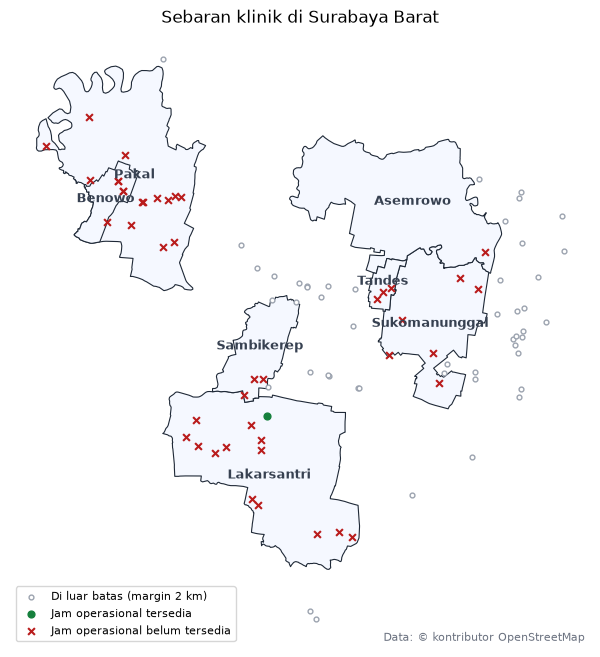

In [8]:
fig, ax = plt.subplots(figsize=(8, 8))
batas.plot(ax=ax, color="#f5f8ff", edgecolor="#1f2937", linewidth=0.8)
dalam = klinik[klinik["Di_Wilayah"]]
luar = klinik[~klinik["Di_Wilayah"]]
punya_jam = dalam["Jadwal_Operasional"].apply(lambda t: dp.parse_jadwal(t) is not None)
if len(luar):
    luar.plot(ax=ax, color="white", edgecolor="#9ca3af", markersize=12, label="Di luar batas (margin 2 km)")
if punya_jam.any():
    dalam[punya_jam].plot(ax=ax, color="#15803d", markersize=24, label="Jam operasional tersedia")
if (~punya_jam).any():
    dalam[~punya_jam].plot(ax=ax, color="#b91c1c", marker="x", markersize=24, label="Jam operasional belum tersedia")
for _, r in batas.iterrows():
    p = r.geometry.representative_point()
    ax.text(p.x, p.y, r["kec"], ha="center", fontsize=9, fontweight="bold", color="#374151")
ax.set_title("Sebaran klinik di Surabaya Barat")
ax.text(0.99, 0.01, "Data: © kontributor OpenStreetMap", transform=ax.transAxes, ha="right", fontsize=8, color="#6b7280")
ax.legend(loc="lower left", fontsize=8)
ax.set_axis_off()
(ROOT / "outputs").mkdir(exist_ok=True)
fig.savefig(ROOT / "outputs" / "peta_data_klinik.png", dpi=200, bbox_inches="tight")
plt.show()

## 8. Pengujian fungsi jam operasional

In [9]:
from datetime import datetime
from zoneinfo import ZoneInfo
now = datetime.now(ZoneInfo("Asia/Jakarta"))
hari, menit = now.weekday(), now.hour * 60 + now.minute
contoh = klinik[klinik["Jadwal_Operasional"] != ""].head(8)
for _, r in contoh.iterrows():
    j = dp.parse_jadwal(r["Jadwal_Operasional"])
    print(f"{r['Nama_Klinik'][:30]:30s} | {dp.NAMA_HARI[hari]}: {dp.teks_jam(j, hari):16s} | buka saat ini: {dp.buka_pada(j, hari, menit)}")

Praktek dokter umum            | Rabu: 05.00–09.00, 17.00–21.00 | buka saat ini: False
Gigi Sehat                     | Rabu: 08.00–13.30, 15.00–21.00 | buka saat ini: False


## 9. Pemanggilan dataset
Dataset final dapat dimuat pada notebook lain tanpa mengambil ulang data dari OSM.

In [10]:
k = dp.muat_klinik()
print(k.crs, "|", len(k), "klinik")
k[["Clinic_ID", "Nama_Klinik", "Alamat", "Kecamatan", "Jenis_Layanan", "Jadwal_Operasional", "jadwal"]].head()

EPSG:32749 | 93 klinik


,Clinic_ID,Nama_Klinik,Alamat,Kecamatan,Jenis_Layanan,Jadwal_Operasional,jadwal
0,K001,BPM Afah Fahmi,Jalan Aswm III no. 8,Asemrowo,Dokter umum,,None
1,K002,Bidan Delima,Puri Lidah Kulon Indah Blok A no.8,Lakarsantri,Dokter umum,,None
2,K003,Posyandu,,Lakarsantri,Dokter umum,,None
3,K004,Posyandu,,Lakarsantri,Dokter umum,,None
4,K005,Posyandu,,Lakarsantri,Dokter umum,,None
